# Gene age: candidate screen

## 1. Data acquisition

This notebook evaluates whether the candidate has an identifiable input-side definition suitable for a separate performance analysis. It stops at that decision where appropriate; no unperformed performance experiment is represented as a negative result.


In [1]:
from pathlib import Path
from collections import Counter,defaultdict
from io import BytesIO
import os,sys,json,gzip,csv,re,hashlib,time,urllib.request,ssl,zipfile,math,platform
for key in ['OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS']:os.environ[key]='1'
import numpy as np
import pandas as pd
from scipy.stats import spearmanr,wilcoxon
from sklearn.metrics import roc_auc_score,average_precision_score
from Bio.Align import substitution_matrices
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display,Image,Markdown
RAW=Path(os.environ.get('AM_RAW_INPUTS','am_public_inputs')).expanduser().resolve()
OUTPUT=Path('calculated_outputs').resolve();RAW.mkdir(parents=True,exist_ok=True);OUTPUT.mkdir(parents=True,exist_ok=True)
STARTED=time.time()
pd.set_option('display.max_colwidth',100)
def show_figure(fig):
    buffer=BytesIO();fig.savefig(buffer,format='png',dpi=150,bbox_inches='tight');display(Image(data=buffer.getvalue()))


In [2]:
SOURCES=[]

def sha256_file(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda:f.read(8*1024*1024),b''):h.update(block)
    return h.hexdigest()
def acquire(source):
    p=RAW/Path(source['path']).name
    if not p.exists():
        partial=p.with_name(p.name+'.notebook-part')
        req=urllib.request.Request(source['url'],headers={'User-Agent':'AlphaMissense-analysis/1.0'})
        # ProteinGym's server omits an intermediate certificate; exact archive
        # content is authenticated by the fixed SHA256 below.
        context=ssl._create_unverified_context() if 'marks.hms.harvard.edu' in source['url'] and source.get('sha256') else None
        with urllib.request.urlopen(req,timeout=180,context=context) as r,partial.open('wb') as f:
            while True:
                b=r.read(4*1024*1024)
                if not b:break
                f.write(b)
        if source.get('sha256') and sha256_file(partial)!=source['sha256']:raise ValueError('Download checksum mismatch: '+p.name)
        if source.get('bytes') and partial.stat().st_size!=source['bytes']:raise ValueError('Download size mismatch: '+p.name)
        partial.replace(p)
    h=sha256_file(p)
    if source.get('sha256') and h!=source['sha256']:raise ValueError('Input checksum mismatch: '+p.name)
    if source.get('bytes') and p.stat().st_size!=source['bytes']:raise ValueError('Input size mismatch: '+p.name)
    return dict(path=p.name,url=source['url'],sha256=h,bytes=p.stat().st_size)
source_receipts=[acquire(s) for s in SOURCES]
display(pd.DataFrame(source_receipts))


""


In [3]:
import urllib.parse
SPECIES=['ptroglodytes','mmusculus','ggallus','drerio','dmelanogaster','scerevisiae']
biomart='https://www.ensembl.org/biomart/martservice'
registry=urllib.request.urlopen(biomart+'?type=registry',timeout=90).read().decode()
assert 'ensembl_mart_116' in registry,'Expected Ensembl Genes release 116; use a matching archived BioMart endpoint.'
queries=[('gene_info',['ensembl_gene_id','entrezgene_id','hgnc_symbol'])]+[('ortho_'+sp,['ensembl_gene_id',sp+'_homolog_ensembl_gene']) for sp in SPECIES]
for name,attributes in queries:
    xml='<?xml version="1.0" encoding="UTF-8"?><!DOCTYPE Query><Query virtualSchemaName="default" formatter="TSV" header="1" uniqueRows="1" count="" datasetConfigVersion="0.6"><Dataset name="hsapiens_gene_ensembl" interface="default">'+''.join('<Attribute name="'+x+'"/>' for x in attributes)+'</Dataset></Query>'
    url=biomart+'?query='+urllib.parse.quote(xml);path=RAW/('ensembl116_'+name+'.tsv');receipt=path.with_suffix('.source.json')
    if path.exists():
        assert receipt.exists(),'Unverified cached BioMart response: '+str(path)
        record=json.loads(receipt.read_text());assert record['url']==url and record['sha256']==sha256_file(path)
    else:
        for attempt in range(4):
            try:
                body=urllib.request.urlopen(url,timeout=180).read()
                assert body.count(bytes([10]))>1000 and b'Query ERROR' not in body and b'<html' not in body
                path.write_bytes(body);break
            except Exception:
                if attempt==3:raise
                time.sleep(5)
        record={'path':path.name,'url':url,'release':116,'sha256':sha256_file(path),'bytes':path.stat().st_size}
        receipt.write_text(json.dumps(record,indent=2))
    source_receipts.append(record)
display(pd.DataFrame(source_receipts))


,path,url,release,sha256,bytes
0,ensembl116_gene_info.tsv,https://www.ensembl.org/biomart/martservice?query=%3C%3Fxml%20version%3D%221.0%22%20encoding%3D%...,116,405fe9469363e4c896607f1f4b460a0a2f5aafcf16bc286946a6e3836bf66a46,2236960
1,ensembl116_ortho_ptroglodytes.tsv,https://www.ensembl.org/biomart/martservice?query=%3C%3Fxml%20version%3D%221.0%22%20encoding%3D%...,116,1826b867b03b6c9bb16f6668d9bd45e3d33be6d6b16cc47f5a5ecba7547c3ed7,1954106
2,ensembl116_ortho_mmusculus.tsv,https://www.ensembl.org/biomart/martservice?query=%3C%3Fxml%20version%3D%221.0%22%20encoding%3D%...,116,f4d68b70840cee47c4351a0016144484f7f960872c39dd681cf2f67bfc3abb7e,2044064
3,ensembl116_ortho_ggallus.tsv,https://www.ensembl.org/biomart/martservice?query=%3C%3Fxml%20version%3D%221.0%22%20encoding%3D%...,116,de81fc669ac7abbe98967cfc78926df2f99b7c0159807ae0af09b1f864c26b2c,1836547
4,ensembl116_ortho_drerio.tsv,https://www.ensembl.org/biomart/martservice?query=%3C%3Fxml%20version%3D%221.0%22%20encoding%3D%...,116,e03833c898213b55a0b2fbc4d42c6e595ab469e444e76e6194c881eeecb04df8,1956494
5,ensembl116_ortho_dmelanogaster.tsv,https://www.ensembl.org/biomart/martservice?query=%3C%3Fxml%20version%3D%221.0%22%20encoding%3D%...,116,2f6d0f8557be182c9bf59f335d3a423c7696b7d16ae20dea6e563a7328c4d57d,1888252
6,ensembl116_ortho_scerevisiae.tsv,https://www.ensembl.org/biomart/martservice?query=%3C%3Fxml%20version%3D%221.0%22%20encoding%3D%...,116,2ebf96509103a64536b51aecb002443612d910aa6347156b2352733e8715d65f,1568049


## 2. Raw processing

Parse Ensembl 116 gene mappings and raw ortholog-presence responses separately for six species. Presence in sampled species is an observed annotation; it is not automatically an inferred age of origin.


In [4]:
gi=pd.read_csv(RAW/'ensembl116_gene_info.tsv',sep='\t',dtype=str);gi.columns=['ensembl','entrez','symbol'];gi=gi.drop_duplicates()
presence={}
for species in SPECIES:
    t=pd.read_csv(RAW/f'ensembl116_ortho_{species}.tsv',sep='\t',dtype=str);t.columns=['ensembl','ortholog'];presence[species]=set(t.loc[t.ortholog.notna() & t.ortholog.ne(''),'ensembl'])
genes=pd.DataFrame({'ensembl':sorted(gi.ensembl.dropna().unique())})
for species in SPECIES:genes[species]=genes.ensembl.isin(presence[species]).astype(int)
genes['species_with_ortholog']=genes[SPECIES].sum(axis=1)
print('Raw ortholog-presence input coverage:');display(genes[SPECIES].sum().to_frame('human_gene_records'))
print('Mapping multiplicity:');display(gi.groupby('ensembl').agg(entrez_ids=('entrez','nunique'),symbols=('symbol','nunique')).describe())


Raw ortholog-presence input coverage:


,human_gene_records
ptroglodytes,23651
mmusculus,19267
ggallus,14429
drerio,14359
dmelanogaster,8999
scerevisiae,3806


Mapping multiplicity:


,entrez_ids,symbols
count,86411.000000,86411.000000
mean,0.426149,0.547997
std,2.706145,0.497740
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.000000,1.000000
75%,1.000000,1.000000
max,208.000000,2.000000


## 3. Axis and levels


An evolutionary-age axis requires a specified phylogenetic tree, orthology definition, treatment of gene loss, and evidence for absence. The six-species presence table supports a breadth diagnostic, not a unique age assignment. The 0–6 presence counts shown below are diagnostic levels, not age bins.


In [5]:
levels=genes.groupby('species_with_ortholog').size().reindex(range(7),fill_value=0).rename('genes').reset_index();display(levels)
axis_defined=False


,species_with_ortholog,genes
0,0,61682
1,1,5021
2,2,3390
3,3,2680
4,4,6019
5,5,5120
6,6,2499


## 4. Model results or released scores

This is a candidate-selection screen. It does not acquire labels or evaluate AlphaMissense performance. No training or fine-tuning is required, and no performance estimate is inferred from annotation availability.


In [6]:
model_evaluation_performed=False
display(pd.DataFrame([{'model_evaluation_performed':False,'fine_tuning_performed':False,'axis_definition_ready':axis_defined}]))


,model_evaluation_performed,fine_tuning_performed,axis_definition_ready
0,False,False,False


## 5. Diagnostic curves and controls

The chart shows raw annotation support, not a spectral performance curve. The controls identify the specific interpretive limitation before any target evaluation.


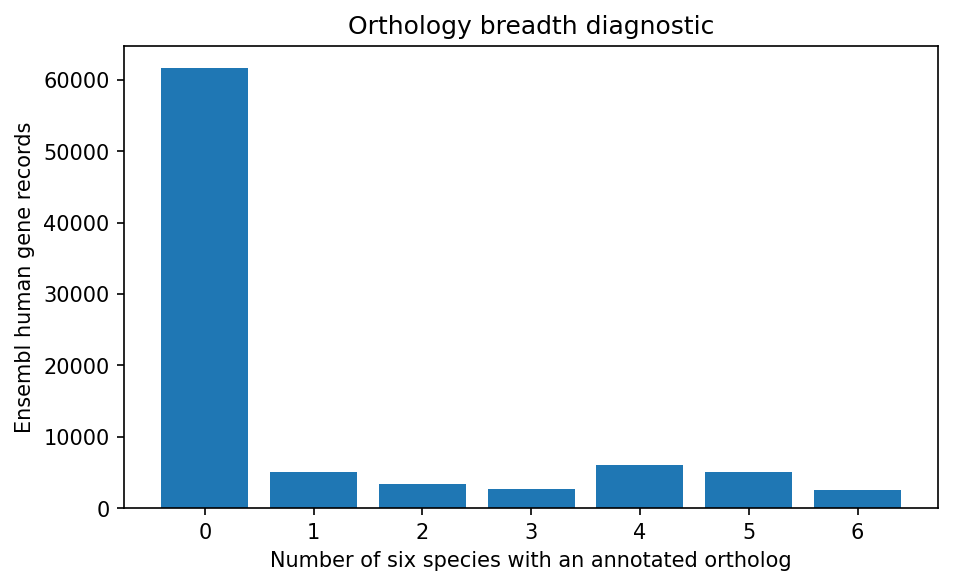

,candidate_controls
age_identifiable_from_presence_alone,False
absence_equivalent_to_gene_origin,False
ontology_and_tree_required,True


In [7]:
fig,ax=plt.subplots(figsize=(7,4));ax.bar(levels.species_with_ortholog,levels.genes);ax.set(xlabel='Number of six species with an annotated ortholog',ylabel='Ensembl human gene records',title='Orthology breadth diagnostic');controls={'age_identifiable_from_presence_alone':False,'absence_equivalent_to_gene_origin':False,'ontology_and_tree_required':True}
show_figure(fig);plt.close(fig);display(pd.Series(controls,name='candidate_controls').to_frame())


## 6. Decision and reason


In [8]:
decision='Defer target scoring: ortholog presence across six sampled species does not uniquely define gene age. Specify a phylogenetic ontology and absence policy before constructing age levels. This is not evidence that AlphaMissense performance is independent of gene age.'
print(decision)
levels.to_csv(OUTPUT/'diagnostic_levels.csv',index=False)
(OUTPUT/'execution.json').write_text(json.dumps({'sources':source_receipts,'decision':decision,'model_evaluation_performed':False,'controls':controls,'host':platform.node(),'elapsed_seconds':time.time()-STARTED,'outputs':{'diagnostic_levels.csv':sha256_file(OUTPUT/'diagnostic_levels.csv')}},indent=2)+'\n')


Defer target scoring: ortholog presence across six sampled species does not uniquely define gene age. Specify a phylogenetic ontology and absence policy before constructing age levels. This is not evidence that AlphaMissense performance is independent of gene age.


5775